# ViT-1D SWAG : entraînement, sélection sur validation et évaluation sur test 




## 1. Imports, environnement et reproductibilité

In [ ]:
import os, sys, random, json
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import scipy.io
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from torch.utils.data import DataLoader, TensorDataset
import hashlib

root_override = os.environ.get('UQ_PROJECT_ROOT')

WINDOWS_PROJECT_ROOT = Path('C:/Users/khadija/Desktop/UQ')
candidates = ([Path(root_override).expanduser()] if root_override
              else [Path.cwd(), *Path.cwd().parents, WINDOWS_PROJECT_ROOT])
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / 'src/net/base_net.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Set UQ_PROJECT_ROOT to the UQ repository.')
DATA_FILE = PROJECT_ROOT / 'data/dataset/Mango/mango_dm_full_outlier_removed2.mat'
sys.path.insert(0, str(PROJECT_ROOT))
from src.net import ViT_1D
from IPython.display import display

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_NAME = 'swag_full_retrain_verified_01'
OUTPUT = PROJECT_ROOT / 'notebook' / RUN_NAME
if OUTPUT.exists():
    raise FileExistsError(f'Dossier de run déjà présent : {OUTPUT}. Choisir un nouveau RUN_NAME')
OUTPUT.mkdir(parents=True, exist_ok=False)
print('Python:', sys.executable)
print('Project:', PROJECT_ROOT)
print('Data:', DATA_FILE)
print('Device:', device)


Python: c:\Users\khadija\Desktop\UQ\venv_khadija\Scripts\python.exe
Project: C:\Users\khadija\Desktop\UQ
Data: C:\Users\khadija\Desktop\UQ\data\dataset\Mango\mango_dm_full_outlier_removed2.mat
Device: cuda


## 2. Architecture et hyperparamètres

In [ ]:
@dataclass
class Config:
    device: str = str(device)
    num_epochs: int = 1000
    classification: bool = False
    save_path: Path = OUTPUT / 'vit_pretrain_best.pth'
    max_loss_plot: float = None
    batch_size: int = 32
    weight_decay: float = 1e-4
    patch_size: int = 128
    dim_embed: int = 128
    trans_layers: int = 6
    heads: int = 8
    mlp_dim: int = 256
    dropout: float = 0.1
    emb_dropout: float = 0.1
    learning_rate: float = 5e-5
    scale_factor: float = 2.0
    swag_start: int = 500
    swag_c_epochs: int = 1
    max_num_models: int = 20
    var_clamp: float = 1e-30
    num_samples_uq: int = 50
    sgd_momentum: float = 0.9

cfg=Config()
assert 0 < cfg.swag_start < cfg.num_epochs
assert cfg.max_num_models >= 2 and cfg.num_samples_uq >= 2
assert cfg.scale_factor > 0 and cfg.swag_c_epochs > 0

SGD_LEARNING_RATES = [5e-5, 1e-4, 5e-4, 1e-3]
BRANCH_SEED = 12345
assert cfg.scale_factor == 2.0


## 3. Chargement, découpage et normalisation des données

In [3]:
def load_mango_data():
    if not DATA_FILE.is_file():
        raise FileNotFoundError(f'Mango data file not found: {DATA_FILE}')
    d = scipy.io.loadmat(str(DATA_FILE))
    Xcal, Ycal = d['SP_all_train'], np.asarray(d['DM_cal']).reshape(-1,1)
    Xtest, Ytest = d['SP_all_test'], np.asarray(d['DM_test']).reshape(-1,1)
    x_train, x_val, y_train, y_val = train_test_split(
        Xcal, Ycal, test_size=.20, random_state=42, shuffle=True)
    mean = np.mean(x_train,axis=0)
    std = np.std(x_train,axis=0)
    std = np.where(std < 1e-12, 1., std)
    make=lambda x,y: TensorDataset(torch.tensor(x,dtype=torch.float32), torch.tensor(y,dtype=torch.float32))
    train_ds,val_ds,test_ds=make(x_train,y_train),make(x_val,y_val),make(Xtest,Ytest)
    gen=torch.Generator().manual_seed(SEED)
    loaders=(DataLoader(train_ds,batch_size=cfg.batch_size,shuffle=True,generator=gen),
             DataLoader(val_ds,batch_size=cfg.batch_size,shuffle=False),
             DataLoader(test_ds,batch_size=cfg.batch_size,shuffle=False))
    print('train/val/test:',len(train_ds),len(val_ds),len(test_ds))
    return loaders,mean,std,x_train.shape[1]

(loaders,mean,std,seq_len)=load_mango_data()
train_loader,val_loader,test_loader=loaders


train/val/test: 7931 1983 1448


## 4. Construction du modèle ViT-1D

In [4]:
def create_model():
    model=ViT_1D(mean=mean, std=std, seq_len=seq_len,patch_size=cfg.patch_size,
        dim_embed=cfg.dim_embed,trans_layers=cfg.trans_layers,heads=cfg.heads,
        mlp_dim=cfg.mlp_dim,out_dims=1,channels=1,
        dropout=cfg.dropout,emb_dropout=cfg.emb_dropout).to(device)
    print('Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))
    return model


## 5. Implémentation de SWAG

In [ ]:
class SWAG(nn.Module):
    def __init__(self, base_model, max_num_models=20, var_clamp=1e-30):
        super().__init__()
        self.base=base_model
        self.max_num_models=max_num_models
        self.var_clamp=var_clamp
        self.param_names=[]
        self.register_buffer('n_models',torch.zeros((),dtype=torch.long))
        for name,p in self.base.named_parameters():
            if not p.requires_grad:
                continue  
            key=name.replace('.','__')
            self.param_names.append((name,key))
            self.register_buffer(key+'_mean',torch.zeros_like(p.detach()))
            self.register_buffer(key+'_sq_mean',torch.zeros_like(p.detach()))
            self.register_buffer(key+'_cov_mat_sqrt',torch.zeros((p.numel(), max_num_models),dtype=p.dtype,device=p.device))

    def forward(self,*args,**kwargs):return self.base(*args,**kwargs)

    @torch.no_grad()
    def collect_model(self, model):
        n=int(self.n_models.item())
        source=dict(model.named_parameters())
        for name,key in self.param_names:
            p=source[name].detach()
            mean=getattr(self,key+'_mean')
            sq=getattr(self,key+'_sq_mean')
            mean.mul_(n/(n+1)).add_(p/(n+1))
            sq.mul_(n/(n+1)).add_(p.square()/(n+1))
            dev=(p-mean).reshape(-1)
            getattr(self,key+'_cov_mat_sqrt')[:,n % self.max_num_models].copy_(dev)
        self.n_models.add_(1)

    @torch.no_grad()
    def sample(self, scale=2.0, cov=True):
        n=int(self.n_models.item()); k=min(n,self.max_num_models)
        if n<2: raise RuntimeError('SWAG exige au moins deux modèles collectés.')
        z2=torch.randn(k,device=next(self.base.parameters()).device) if cov else None
        params=dict(self.base.named_parameters())
        for name,key in self.param_names:
            mean=getattr(self,key+'_mean')
            sq=getattr(self,key+'_sq_mean')
            var=(sq-mean.square()).clamp_min(self.var_clamp)
            z1=torch.randn_like(mean)
            perturb=(1/np.sqrt(2))*torch.sqrt(var)*z1 if cov else torch.sqrt(var)*z1
            if cov:
                mat=getattr(self,key+'_cov_mat_sqrt')[:,:k]
                perturb=perturb + (mat@z2).reshape_as(mean)/np.sqrt(2*(k-1))
            params[name].copy_(mean + scale*perturb)

    @torch.no_grad()
    def set_swa_mean(self):
        params=dict(self.base.named_parameters())
        for name,key in self.param_names:
            params[name].copy_(getattr(self,key+'_mean'))


## 6. Fonctions d’entraînement et de validation

In [ ]:
class RegressionTrainer:
    
    def __init__(self, model, optimizer, criterion, train_loader, val_loader, config):
        self.model, self.optimizer, self.criterion = model, optimizer, criterion
        self.train_loader, self.val_loader = train_loader, val_loader
        self.device = torch.device(config.device)

    def train_one_epoch(self):
        self.model.train()
        total = 0.0
        for x, y in self.train_loader:
            x, y = x.to(self.device), y.to(self.device)
            self.optimizer.zero_grad(set_to_none=True)
            loss = self.criterion(self.model(x.unsqueeze(1)), y)
            loss.backward()
            self.optimizer.step()
            total += loss.detach().item() * x.size(0)
        return total / len(self.train_loader.dataset)

    @torch.no_grad()
    def evaluate(self):
        self.model.eval()
        total = 0.0
        for x, y in self.val_loader:
            x, y = x.to(self.device), y.to(self.device)
            total += self.criterion(self.model(x.unsqueeze(1)), y).item() * x.size(0)
        return total / len(self.val_loader.dataset), None


## 7. Prédictions stochastiques et calcul des incertitudes

In [7]:
@torch.no_grad()
def predict_validation(swag, loader, scale, num_samples=50, seed=12345):
    swag.eval()
    targets = np.concatenate([y.numpy().reshape(-1) for _, y in loader])
    draws = []
    try:
        with torch.random.fork_rng(devices=[device.index or 0] if device.type == 'cuda' else []):
            torch.manual_seed(seed)
            if device.type == 'cuda':
                torch.cuda.manual_seed_all(seed)
            for sample_index in range(1 if scale == 0 else num_samples):
                if scale == 0:
                    swag.set_swa_mean()
                else:
                    swag.sample(scale=scale, cov=True)
                batches = []
                for x, _ in loader:
                    x = x.to(device)
                    if x.ndim == 2:
                        x = x.unsqueeze(1)
                    batches.append(swag(x).reshape(-1).cpu().numpy())
                draws.append(np.concatenate(batches))
    finally:
        swag.set_swa_mean()
    draws = np.stack(draws)
    mu = draws.mean(axis=0)
    epi = draws.std(axis=0, ddof=1) if len(draws) > 1 else np.zeros_like(mu)
    return targets, mu, epi


def summarize(y, mu, epi, scale):
    resid = y - mu
    sigma_resid = float(np.std(resid, ddof=1))
    sigma_total = np.sqrt(sigma_resid**2 + epi**2)
    return dict(method='SWA' if scale == 0 else 'SWAG', scale=scale,
                RMSE=float(np.sqrt(mean_squared_error(y, mu))), R2=float(r2_score(y, mu)),
                bias=float(np.mean(mu-y)), mean_sigma_epistemic=float(epi.mean()),
                sigma_resid_val=sigma_resid,
                coverage_residual_3sigma=float(np.mean(np.abs(resid) <= 3*sigma_resid)*100),
                coverage_combined_3sigma=float(np.mean(np.abs(resid) <= 3*sigma_total)*100),
                mean_width_combined_3sigma=float(np.mean(6*sigma_total)))


## 8. Préentraînement Adam partagé 



In [8]:


def reset_branch_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    train_loader.generator.manual_seed(seed)

protocol = {k: str(v) if isinstance(v, Path) else v for k,v in vars(cfg).items()}
protocol.pop('save_path', None)
protocol['seed'] = SEED
protocol['data_sha256'] = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
protocol['model_sha256'] = hashlib.sha256((PROJECT_ROOT/'src/net/base_net.py').read_bytes()).hexdigest()
pretrain_file = OUTPUT / 'shared_adam_checkpoint.pt'
if pretrain_file.exists():
    raise FileExistsError(f'Checkpoint Adam déjà présent dans ce run : {pretrain_file}')
else:
    reset_branch_seed(SEED)
    model = create_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
    trainer = RegressionTrainer(model, optimizer, nn.MSELoss(), train_loader, val_loader, cfg)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.swag_start)
    adam_rows = []
    for epoch in range(cfg.swag_start):
        train_loss = trainer.train_one_epoch()
        scheduler.step()
        val_loss, _ = trainer.evaluate()
        adam_rows.append(dict(epoch=epoch+1, train_loss=float(train_loss), val_loss=float(val_loss)))
        if (epoch+1) % 50 == 0:
            print('Adam', epoch+1, 'val MSE', float(val_loss), flush=True)
    adam_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    torch.save(dict(protocol=protocol, model_state_dict=adam_state), pretrain_file)
    pd.DataFrame(adam_rows).to_csv(OUTPUT/'shared_adam_history.csv', index=False)


Trainable parameters: 1990401
Adam 50 val MSE 0.43807721351410966
Adam 100 val MSE 0.34181265231640845
Adam 150 val MSE 0.29774646763842455
Adam 200 val MSE 0.2860946012186511
Adam 250 val MSE 0.28670911345888256
Adam 300 val MSE 0.2800473627106926
Adam 350 val MSE 0.26444037384867847
Adam 400 val MSE 0.24986293237887425
Adam 450 val MSE 0.25322829407089836
Adam 500 val MSE 0.2480482832837213


## 9. Entraînement des branches SGD et comparaison sur validation




In [ ]:
rows = []
for lr in SGD_LEARNING_RATES:
    tag = f'sgd_lr_{lr:g}'
    reset_branch_seed(BRANCH_SEED)
    model = create_model()
    model.load_state_dict(adam_state, strict=True)
    
    reset_branch_seed(BRANCH_SEED)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr,
                                momentum=cfg.sgd_momentum, weight_decay=cfg.weight_decay)
    trainer = RegressionTrainer(model, optimizer, nn.MSELoss(), train_loader, val_loader, cfg)
    swag = SWAG(model, max_num_models=cfg.max_num_models, var_clamp=cfg.var_clamp).to(device)
    history = []
    for epoch in range(cfg.num_epochs-cfg.swag_start):
        train_loss = trainer.train_one_epoch()
        val_loss, _ = trainer.evaluate()
        if not np.isfinite(float(train_loss)) or not np.isfinite(float(val_loss)):
            raise RuntimeError(f'Nonfinite loss: LR={lr}, epoch={epoch+1}')
        history.append(dict(epoch=cfg.swag_start+epoch+1, learning_rate=lr,
                            train_loss=float(train_loss), val_loss=float(val_loss)))
        if (epoch+1) % cfg.swag_c_epochs == 0:
            swag.collect_model(model)
        if (epoch+1) % 50 == 0:
            print(tag, epoch+1, 'val MSE', float(val_loss), flush=True)
    pd.DataFrame(history).to_csv(OUTPUT/f'{tag}_history.csv', index=False)
    checkpoint_path = OUTPUT / f'{tag}_checkpoint.pt'
    if checkpoint_path.exists():
        raise FileExistsError(checkpoint_path)
    torch.save(dict(swag_state_dict=swag.state_dict(), configuration=vars(cfg),
                    sgd_learning_rate=lr, protocol=protocol, branch_seed=BRANCH_SEED),
               checkpoint_path)
    for scale in [0.0, cfg.scale_factor]:
        y, mu, epi = predict_validation(swag, val_loader, scale, cfg.num_samples_uq, BRANCH_SEED)
        row = summarize(y, mu, epi, scale)
        row.update(sgd_learning_rate=lr, snapshots=int(swag.n_models.item()))
        rows.append(row)
        np.savez(OUTPUT/f'{tag}_scale_{scale:g}_validation.npz', target=y,
                 prediction=mu, sigma_epistemic=epi)
    pd.DataFrame(rows).to_csv(OUTPUT/'validation_lr_metrics.csv', index=False)
    del trainer, optimizer, swag, model
    if device.type == 'cuda':
        torch.cuda.empty_cache()
comparison = pd.DataFrame(rows)
swag_ranking = comparison[comparison.method == 'SWAG'].sort_values('RMSE')
display(swag_ranking)
display(comparison[comparison.method == 'SWA'].sort_values('RMSE'))
print('Best SGD LR on validation:', swag_ranking.iloc[0].sgd_learning_rate)


Trainable parameters: 1990401
sgd_lr_5e-05 50 val MSE 0.25025039271038707
sgd_lr_5e-05 100 val MSE 0.24499982379778912
sgd_lr_5e-05 150 val MSE 0.25323817459279335
sgd_lr_5e-05 200 val MSE 0.24745537570583298
sgd_lr_5e-05 250 val MSE 0.24881922886098687
sgd_lr_5e-05 300 val MSE 0.23860196791029434
sgd_lr_5e-05 350 val MSE 0.24323703393723348
sgd_lr_5e-05 400 val MSE 0.25091944800232374
sgd_lr_5e-05 450 val MSE 0.2500850731489097
sgd_lr_5e-05 500 val MSE 0.24403928888306975
Trainable parameters: 1990401
sgd_lr_0.0001 50 val MSE 0.2514441380567522
sgd_lr_0.0001 100 val MSE 0.24877749520964051
sgd_lr_0.0001 150 val MSE 0.25078130742996196
sgd_lr_0.0001 200 val MSE 0.24691952640999465
sgd_lr_0.0001 250 val MSE 0.25573910737482514
sgd_lr_0.0001 300 val MSE 0.2380470861570437
sgd_lr_0.0001 350 val MSE 0.23696165630688765
sgd_lr_0.0001 400 val MSE 0.2570359850329578
sgd_lr_0.0001 450 val MSE 0.2459801005718988
sgd_lr_0.0001 500 val MSE 0.24362384703384166
Trainable parameters: 1990401
sgd_lr_

,method,scale,RMSE,R2,bias,mean_sigma_epistemic,sigma_resid_val,coverage_residual_3sigma,coverage_combined_3sigma,mean_width_combined_3sigma,sgd_learning_rate,snapshots
5,SWAG,2.0,0.464685,0.961843,0.008207,0.348475,0.464730,98.789713,99.546142,3.502139,0.00050,500
3,SWAG,2.0,0.489402,0.957675,0.083213,0.129404,0.482397,98.688855,98.840141,3.008300,0.00010,500
1,SWAG,2.0,0.493953,0.956885,0.089132,0.091753,0.485967,98.739284,98.840141,2.973607,0.00005,500
7,SWAG,2.0,0.743157,0.902406,-0.587210,1.592322,0.455600,96.469995,100.000000,9.939162,0.00100,500


,method,scale,RMSE,R2,bias,mean_sigma_epistemic,sigma_resid_val,coverage_residual_3sigma,coverage_combined_3sigma,mean_width_combined_3sigma,sgd_learning_rate,snapshots
4,SWA,0.0,0.491955,0.957233,0.099789,0.0,0.481849,98.890570,98.890570,2.891095,0.00050,500
2,SWA,0.0,0.495007,0.956700,0.084725,0.0,0.487826,98.739284,98.739284,2.926955,0.00010,500
0,SWA,0.0,0.496039,0.956520,0.084504,0.0,0.488912,98.789713,98.789713,2.933471,0.00005,500
6,SWA,0.0,0.548052,0.946923,0.270513,0.0,0.476758,98.688855,98.688855,2.860550,0.00100,500


Best SGD LR on validation: 0.0005


## 10. Comparaison SWA et SWAG selon le learning rate

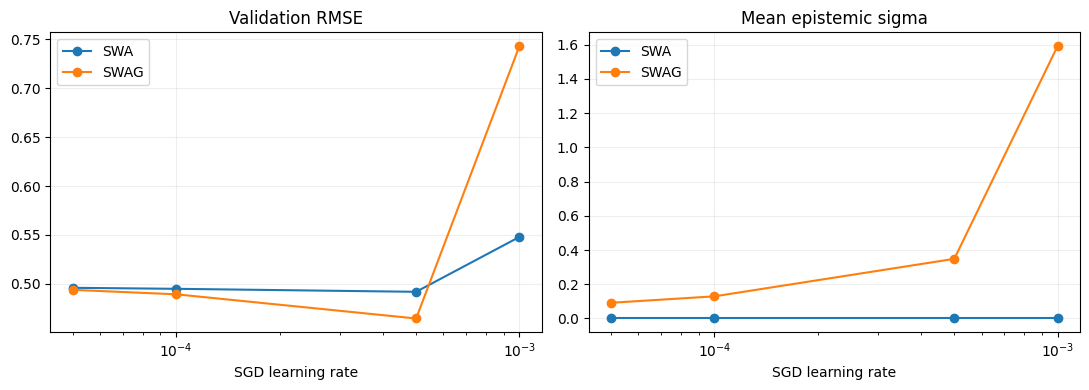

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for method, group in comparison.groupby('method'):
    group = group.sort_values('sgd_learning_rate')
    axes[0].plot(group.sgd_learning_rate, group.RMSE, 'o-', label=method)
    axes[1].plot(group.sgd_learning_rate, group.mean_sigma_epistemic, 'o-', label=method)
for ax, title in zip(axes, ['Validation RMSE', 'Mean epistemic sigma']):
    ax.set_xscale('log'); ax.set_xlabel('SGD learning rate')
    ax.set_title(title); ax.grid(alpha=.2); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT/'sgd_lr_comparison.png', dpi=200); plt.show()
with (OUTPUT/'comparison_protocol.json').open('w', encoding='utf-8') as f:
    json.dump(dict(configuration=protocol, sgd_learning_rates=SGD_LEARNING_RATES,
                   branch_seed=BRANCH_SEED, selection_metric='validation RMSE',
                   scale_convention='perturbation multiplier; covariance factor=scale**2',
                   test_evaluated=False), f, indent=2)


## 11. Évaluation des 12 couples LR × scale sur validation



In [ ]:

GRID_SCALES = [0.5, 1.0, 2.0]
GRID_SAMPLES = cfg.num_samples_uq
GRID_OUTPUT = OUTPUT / "validation_lr_scale_grid"
GRID_OUTPUT.mkdir(parents=True, exist_ok=True)

expected_targets = np.concatenate([
    y.numpy().reshape(-1) for _, y in val_loader
])

grid_rows = []
checkpoint_hashes = {}
for grid_lr in SGD_LEARNING_RATES:
    checkpoint_file = OUTPUT / f"sgd_lr_{grid_lr:g}_checkpoint.pt"
    if not checkpoint_file.is_file():
        raise FileNotFoundError(f"Checkpoint SGD manquant : {checkpoint_file}")
    checkpoint_hash = hashlib.sha256(checkpoint_file.read_bytes()).hexdigest()
    checkpoint_hashes[grid_lr] = checkpoint_hash
    checkpoint = torch.load(checkpoint_file, map_location="cpu", weights_only=False)
    if not np.isclose(float(checkpoint['sgd_learning_rate']), grid_lr, rtol=0, atol=1e-12):
        raise ValueError(f"Learning rate incohérent dans {checkpoint_file}")
    if checkpoint.get('protocol') != protocol:
        raise ValueError(f"Protocole différent pour {checkpoint_file}")
    grid_model = create_model()
    grid_swag = SWAG(grid_model, max_num_models=cfg.max_num_models,
                     var_clamp=cfg.var_clamp).to(device)
    grid_swag.load_state_dict(checkpoint['swag_state_dict'], strict=True)
    del checkpoint
    try:
        for grid_scale in GRID_SCALES:
          
            gy, gmu, gepi = predict_validation(
                grid_swag, val_loader, scale=grid_scale,
                num_samples=GRID_SAMPLES, seed=BRANCH_SEED
            )
            gy, gmu, gepi = (np.asarray(a).reshape(-1) for a in (gy, gmu, gepi))
            np.testing.assert_array_equal(gy, expected_targets)
            if not (gy.shape == gmu.shape == gepi.shape and
                    np.isfinite(gmu).all() and np.isfinite(gepi).all() and
                    np.all(gepi >= 0)):
                raise ValueError('Prédictions de validation invalides')
            prediction_file = GRID_OUTPUT / f"lr_{grid_lr:g}_scale_{grid_scale:g}.npz"
            if prediction_file.exists():
                raise FileExistsError(prediction_file)
            np.savez(prediction_file, target=gy, prediction=gmu,
                     sigma_epistemic=gepi,
                     checkpoint_sha256=np.array(checkpoint_hash),
                     mc_seed=np.array(BRANCH_SEED), num_samples=np.array(GRID_SAMPLES),
                     sgd_learning_rate=np.array(grid_lr), scale=np.array(grid_scale))
            row = summarize(gy, gmu, gepi, grid_scale)
            row.update(sgd_learning_rate=grid_lr, num_samples=GRID_SAMPLES,
                       mc_seed=BRANCH_SEED, checkpoint_sha256=checkpoint_hash)
            grid_rows.append(row)
            print(f"LR={grid_lr:g}, scale={grid_scale:g}: nouvelle inférence, RMSE={row['RMSE']:.6f}")
    finally:
        del grid_swag, grid_model
        if device.type == 'cuda':
            torch.cuda.empty_cache()

grid_results = pd.DataFrame(grid_rows)

csv_file = GRID_OUTPUT / "validation_lr_scale_metrics.csv"

if csv_file.exists():
    raise FileExistsError(csv_file)
grid_results.to_csv(csv_file, index=False)
print('Grille calculée depuis les checkpoints de cette exécution :', csv_file)

display(
    grid_results.sort_values(
        ["RMSE", "sgd_learning_rate", "scale"]
    )
)

best = grid_results.sort_values(
    ["RMSE", "sgd_learning_rate", "scale"]
).iloc[0]

print(
    "Meilleur couple selon la validation :",
    f"LR={best.sgd_learning_rate:g},",
    f"scale={best.scale:g},",
    f"RMSE={best.RMSE:.6f}",
)

Trainable parameters: 1990401
LR=5e-05, scale=0.5: nouvelle inférence, RMSE=0.495846
LR=5e-05, scale=1: nouvelle inférence, RMSE=0.495409
LR=5e-05, scale=2: nouvelle inférence, RMSE=0.493953
Trainable parameters: 1990401
LR=0.0001, scale=0.5: nouvelle inférence, RMSE=0.494288
LR=0.0001, scale=1: nouvelle inférence, RMSE=0.493005
LR=0.0001, scale=2: nouvelle inférence, RMSE=0.489402
Trainable parameters: 1990401
LR=0.0005, scale=0.5: nouvelle inférence, RMSE=0.489989
LR=0.0005, scale=1: nouvelle inférence, RMSE=0.482222
LR=0.0005, scale=2: nouvelle inférence, RMSE=0.464685
Trainable parameters: 1990401
LR=0.001, scale=0.5: nouvelle inférence, RMSE=0.528712
LR=0.001, scale=1: nouvelle inférence, RMSE=0.473028
LR=0.001, scale=2: nouvelle inférence, RMSE=0.743157
Grille calculée depuis les checkpoints de cette exécution : C:\Users\khadija\Desktop\UQ\notebook\swag_full_retrain_verified_01\validation_lr_scale_grid\validation_lr_scale_metrics.csv


,method,scale,RMSE,R2,bias,mean_sigma_epistemic,sigma_resid_val,coverage_residual_3sigma,coverage_combined_3sigma,mean_width_combined_3sigma,sgd_learning_rate,num_samples,mc_seed,checkpoint_sha256
8,SWAG,2.0,0.464685,0.961843,0.008207,0.348475,0.464730,98.789713,99.546142,3.502139,0.00050,50,12345,b1f4495941c83fa08699b6736e97d048a48c825934dc2d...
10,SWAG,1.0,0.473028,0.960460,0.079423,0.445615,0.466430,98.940998,99.697428,3.873681,0.00100,50,12345,8d09e467fe8bf08c50d9529328af01fad737c6c70f8308...
7,SWAG,1.0,0.482222,0.958908,0.083433,0.156308,0.475070,98.840141,99.142713,3.009117,0.00050,50,12345,b1f4495941c83fa08699b6736e97d048a48c825934dc2d...
5,SWAG,2.0,0.489402,0.957675,0.083213,0.129404,0.482397,98.688855,98.840141,3.008300,0.00010,50,12345,066aa3ed5277c7867d1789c3eff0deed217e6dbc2ff439...
6,SWAG,0.5,0.489989,0.957574,0.099026,0.075984,0.479999,98.840141,98.940998,2.918564,0.00050,50,12345,b1f4495941c83fa08699b6736e97d048a48c825934dc2d...
4,SWAG,1.0,0.493005,0.957050,0.083555,0.065123,0.485995,98.688855,98.789713,2.945389,0.00010,50,12345,066aa3ed5277c7867d1789c3eff0deed217e6dbc2ff439...
2,SWAG,2.0,0.493953,0.956885,0.089132,0.091753,0.485967,98.739284,98.840141,2.973607,0.00005,50,12345,250f85d60cff5afe3e33383dcbe62c4d7266570466abf8...
3,SWAG,0.5,0.494288,0.956826,0.084046,0.032623,0.487213,98.688855,98.739284,2.930697,0.00010,50,12345,066aa3ed5277c7867d1789c3eff0deed217e6dbc2ff439...
1,SWAG,1.0,0.495409,0.956630,0.086496,0.045853,0.487922,98.739284,98.789713,2.942113,0.00005,50,12345,250f85d60cff5afe3e33383dcbe62c4d7266570466abf8...
0,SWAG,0.5,0.495846,0.956553,0.085423,0.022917,0.488556,98.789713,98.789713,2.934985,0.00005,50,12345,250f85d60cff5afe3e33383dcbe62c4d7266570466abf8...


Meilleur couple selon la validation : LR=0.0005, scale=2, RMSE=0.464685


## 12. Heatmaps des résultats de validation


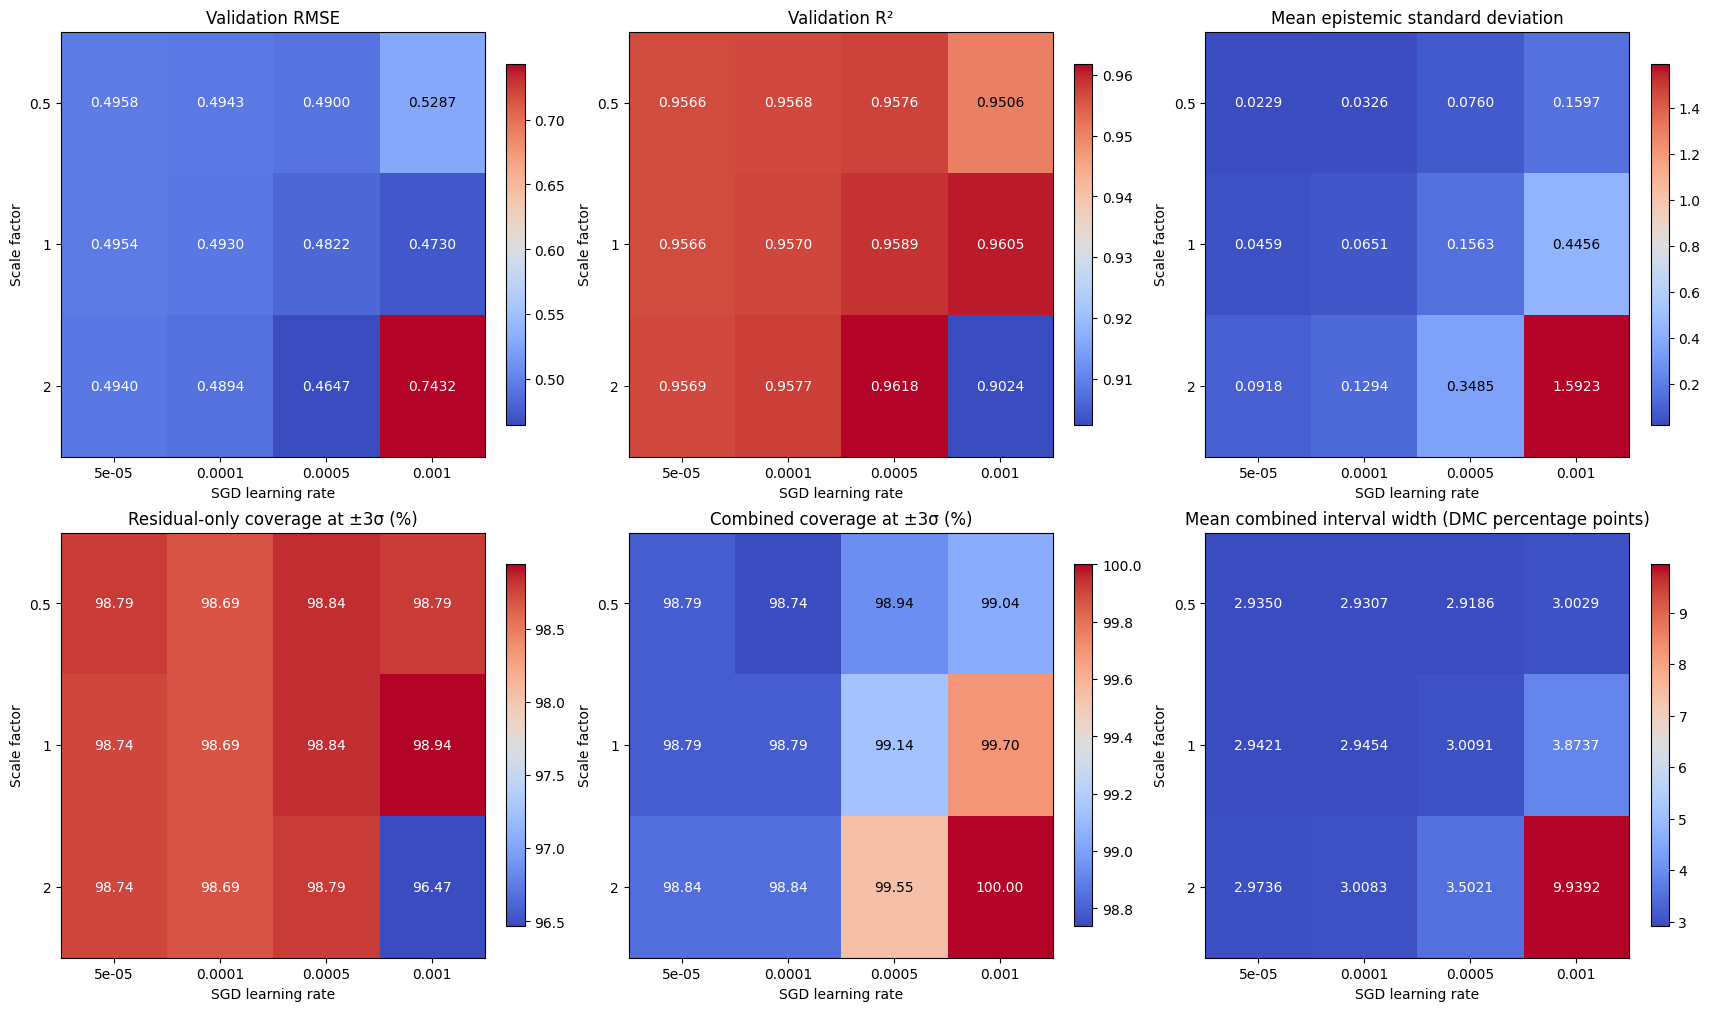

In [12]:
csv_file = (
    OUTPUT / "validation_lr_scale_grid"
    / "validation_lr_scale_metrics.csv"
)
if not csv_file.is_file():
    raise FileNotFoundError(f"Résultats sauvegardés introuvables : {csv_file}")

results = pd.read_csv(csv_file)
scales = [0.5, 1.0, 2.0]

if len(results) != 12 or results.duplicated(
    ["sgd_learning_rate", "scale"]
).any():
    raise ValueError("La grille doit contenir 12 couples LR × scale uniques.")

metrics = [
    ("RMSE", "Validation RMSE"),
    ("R2", "Validation R²"),
    ("mean_sigma_epistemic", "Mean epistemic standard deviation"),
    ("coverage_residual_3sigma", "Residual-only coverage at ±3σ (%)"),
    ("coverage_combined_3sigma", "Combined coverage at ±3σ (%)"),
    ("mean_width_combined_3sigma",
     "Mean combined interval width (DMC percentage points)"),
]

cmap = plt.get_cmap("coolwarm")  
fig, axes = plt.subplots(
    2, 3, figsize=(17, 10), constrained_layout=True
)

for ax, (metric, title) in zip(axes.flat, metrics):
    table = results.pivot(
        index="scale",
        columns="sgd_learning_rate",
        values=metric,
    ).reindex(index=scales, columns=SGD_LEARNING_RATES)

    values = table.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f"Valeurs manquantes ou invalides pour {metric}.")

    im = ax.imshow(values, cmap=cmap, aspect="auto")

    ax.set_xticks(
        range(len(SGD_LEARNING_RATES)),
        [f"{lr:g}" for lr in SGD_LEARNING_RATES],
    )
    ax.set_yticks(range(len(scales)), [f"{s:g}" for s in scales])
    ax.set(
        xlabel="SGD learning rate",
        ylabel="Scale factor",
        title=title,
    )

    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            value = values[row, col]
            rgba = cmap(im.norm(value))
            luminance = (
                0.299 * rgba[0]
                + 0.587 * rgba[1]
                + 0.114 * rgba[2]
            )
            label = f"{value:.2f}" if "coverage" in metric else f"{value:.4f}"
            ax.text(
                col, row, label,
                ha="center", va="center",
                color="black" if luminance > 0.55 else "white",
                fontsize=10,
            )

    fig.colorbar(im, ax=ax, shrink=0.85)

plt.show()

## 13. Évaluation test de la configuration sélectionnée



Configuration sélectionnée AVANT test : 0.0005 2.0 RMSE validation = 0.4646853168951906
Trainable parameters: 1990401


,dataset,sgd_learning_rate,scale,num_samples,mc_seed,RMSE,R2,coverage_3sigma,bias,sigma_resid_val,mean_sigma_epistemic,mean_sigma_total,mean_interval_width
0,test,0.0005,2.0,50,12345,0.952797,0.872522,95.234807,0.088619,0.46473,0.413513,0.625814,3.754886


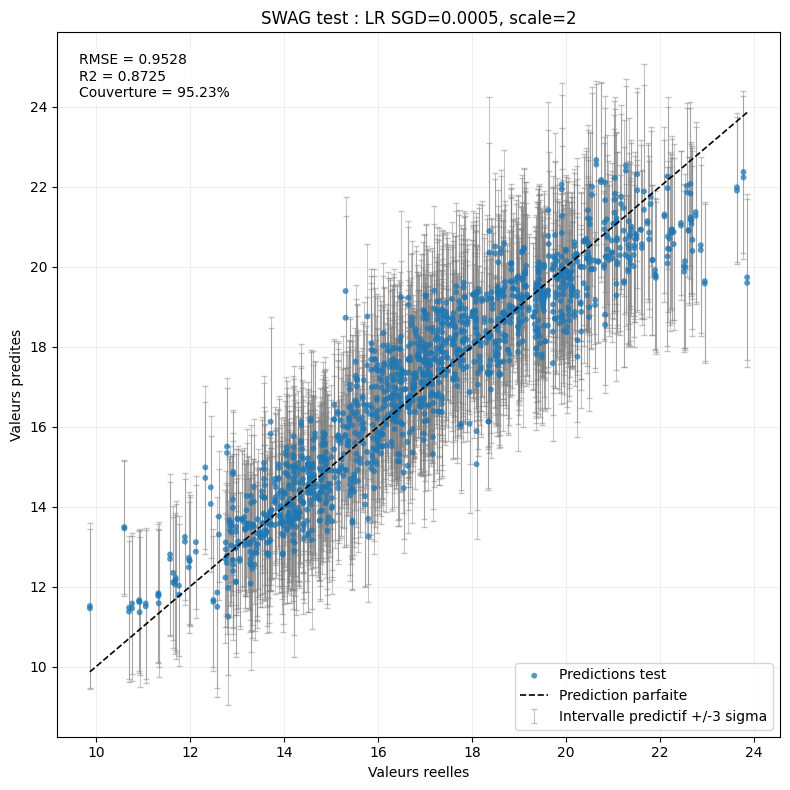

Saved test results: C:\Users\khadija\Desktop\UQ\notebook\swag_full_retrain_verified_01


In [ ]:


if len(grid_results) != len(SGD_LEARNING_RATES) * len(GRID_SCALES):
    raise ValueError('Grille de validation incomplète')
selected = grid_results.sort_values(['RMSE', 'sgd_learning_rate', 'scale']).iloc[0]
BEST_SGD_LR = float(selected['sgd_learning_rate'])
TEST_SCALE = float(selected['scale'])
print('Configuration sélectionnée AVANT test :', BEST_SGD_LR, TEST_SCALE,
      'RMSE validation =', float(selected['RMSE']))
best_tag = f'sgd_lr_{BEST_SGD_LR:g}'
best_checkpoint_file = OUTPUT / f'{best_tag}_checkpoint.pt'
validation_file = GRID_OUTPUT / f'lr_{BEST_SGD_LR:g}_scale_{TEST_SCALE:g}.npz'
for required in [best_checkpoint_file, validation_file]:
    if not required.is_file():
        raise FileNotFoundError(f'Required saved result not found: {required}')

best_checkpoint = torch.load(best_checkpoint_file, map_location='cpu', weights_only=False)
if not np.isclose(best_checkpoint['sgd_learning_rate'], BEST_SGD_LR):
    raise ValueError('Le taux d’apprentissage SGD enregistré dans le checkpoint ne correspond pas à celui de la configuration sélectionnée.')
expected_config = best_checkpoint['configuration']
for key in ['patch_size', 'dim_embed', 'trans_layers', 'heads', 'mlp_dim',
            'dropout', 'emb_dropout', 'max_num_models']:
    if getattr(cfg, key) != expected_config[key]:
        raise ValueError(f'Configuration mismatch for {key}.')
test_model = create_model()
test_swag = SWAG(test_model, max_num_models=cfg.max_num_models,
                 var_clamp=cfg.var_clamp).to(device)
test_swag.load_state_dict(best_checkpoint['swag_state_dict'], strict=True)
del best_checkpoint


with np.load(validation_file, allow_pickle=False) as val_saved:
    actual_hash = hashlib.sha256(best_checkpoint_file.read_bytes()).hexdigest()
    if str(val_saved['checkpoint_sha256'].item()) != actual_hash:
        raise ValueError('Les prédictions de validation ne correspondent pas au checkpoint sélectionné.')
    if not np.isclose(float(val_saved['sgd_learning_rate']), BEST_SGD_LR):
        raise ValueError('Learning rate incorrect dans le fichier validation.')
    if not np.isclose(float(val_saved['scale']), TEST_SCALE):
        raise ValueError('Scale incorrect dans le fichier validation.')
    sigma_resid_val_test = float(np.std(
        val_saved['target'] - val_saved['prediction'], ddof=1))
test_y, test_mu, test_epi = predict_validation(
    test_swag, test_loader, TEST_SCALE, cfg.num_samples_uq, BRANCH_SEED)
test_sigma_total = np.sqrt(sigma_resid_val_test**2 + test_epi**2)
test_lower = test_mu - 3 * test_sigma_total
test_upper = test_mu + 3 * test_sigma_total
test_rmse = float(np.sqrt(mean_squared_error(test_y, test_mu)))
test_r2 = float(r2_score(test_y, test_mu))
test_coverage = float(np.mean((test_y >= test_lower) & (test_y <= test_upper)) * 100)
test_metrics = pd.DataFrame([dict(
    dataset='test', sgd_learning_rate=BEST_SGD_LR, scale=TEST_SCALE,
    num_samples=cfg.num_samples_uq, mc_seed=BRANCH_SEED,
    RMSE=test_rmse, R2=test_r2, coverage_3sigma=test_coverage,
    bias=float(np.mean(test_mu-test_y)), sigma_resid_val=sigma_resid_val_test,
    mean_sigma_epistemic=float(test_epi.mean()),
    mean_sigma_total=float(test_sigma_total.mean()),
    mean_interval_width=float(np.mean(test_upper-test_lower)))])
display(test_metrics)
test_metrics.to_csv(OUTPUT / 'best_sgd_test_metrics.csv', index=False)
with (OUTPUT / 'selected_configuration.json').open('x', encoding='utf-8') as f:
    json.dump(dict(sgd_learning_rate=BEST_SGD_LR, scale=TEST_SCALE,
                   validation_rmse=float(selected['RMSE']),
                   checkpoint_sha256=hashlib.sha256(best_checkpoint_file.read_bytes()).hexdigest(),
                   data_sha256=protocol['data_sha256'],
                   model_sha256=protocol['model_sha256'],
                   seed=SEED, branch_seed=BRANCH_SEED), f, indent=2)
np.savez(OUTPUT / 'best_sgd_test_predictions.npz',
         target=test_y, prediction=test_mu, sigma_epistemic=test_epi,
         sigma_resid_val=sigma_resid_val_test, sigma_total=test_sigma_total,
         interval_lower=test_lower, interval_upper=test_upper,
         sgd_learning_rate=BEST_SGD_LR, scale=TEST_SCALE, mc_seed=BRANCH_SEED)

fig, ax = plt.subplots(figsize=(8, 8))

ax.errorbar(test_y, test_mu, yerr=3*test_sigma_total, fmt='none',
            ecolor='gray', elinewidth=0.8, alpha=0.45, capsize=2,
            label='Intervalle predictif +/-3 sigma', zorder=1)
ax.scatter(test_y, test_mu, color='tab:blue', s=18, alpha=0.75,
           edgecolors='none', label='Predictions test', zorder=2)
limits = [float(min(test_y.min(), test_mu.min())),
          float(max(test_y.max(), test_mu.max()))]
ax.plot(limits, limits, 'k--', linewidth=1.2, label='Prediction parfaite', zorder=3)
ax.set(xlabel='Valeurs reelles', ylabel='Valeurs predites',
       title=f'SWAG test : LR SGD={BEST_SGD_LR:g}, scale={TEST_SCALE:g}')
ax.text(0.03, 0.97,
        f'RMSE = {test_rmse:.4f}\nR2 = {test_r2:.4f}\nCouverture = {test_coverage:.2f}%',
        transform=ax.transAxes, va='top',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
ax.grid(alpha=0.2)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(OUTPUT / 'best_sgd_test_predicted_vs_real.png', dpi=300)
fig.savefig(OUTPUT / 'best_sgd_test_predicted_vs_real.pdf')
plt.show()
print('Saved test results:', OUTPUT)
